# Monte-Carlo-Simulation: Tore bei einem Fußballspiel

## Fragestellung

Angenommen, eine Fußballmannschaft hat in einem Spiel **20 Torschüsse**.  
Jeder Torschuss führt mit einer Wahrscheinlichkeit von **12 %** zu einem Tor.

**Frage:**  
Wie wahrscheinlich ist es, dass die Mannschaft in diesem Spiel **mindestens 3 Tore** erzielt?

Diese Wahrscheinlichkeit wird mithilfe einer **Monte-Carlo-Simulation** geschätzt. Dabei werden sehr viele Spiele zufällig simuliert und anschließend ausgewertet.


## Idee der Simulation

Für jedes simulierte Spiel gilt:

- Es gibt 20 Torschüsse.
- Jeder Torschuss wird zufällig als Tor oder kein Tor bewertet.
- Die Torwahrscheinlichkeit pro Schuss beträgt 12 %.
- Am Ende wird gezählt, wie viele Tore in einem Spiel gefallen sind.

Danach wird berechnet:

- die Wahrscheinlichkeit für mindestens 3 Tore,
- der Mittelwert der erzielten Tore,
- die Standardabweichung der erzielten Tore,
- eine grafische Darstellung der Ergebnisse.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Damit die Simulation reproduzierbar ist
np.random.seed(42)

# Parameter der Simulation
anzahl_simulationen = 100_000
torschuesse_pro_spiel = 20
torwahrscheinlichkeit = 0.12

# Monte-Carlo-Simulation:
# Für jedes Spiel wird simuliert, wie viele der 20 Schüsse ein Tor werden.
tore_pro_spiel = np.random.binomial(
    n=torschuesse_pro_spiel,
    p=torwahrscheinlichkeit,
    size=anzahl_simulationen
)

# Erste 10 Simulationsergebnisse anzeigen
tore_pro_spiel[:10]


array([2, 5, 3, 3, 1, 1, 0, 4, 3, 3], dtype=int32)

## Berechnung der gesuchten Wahrscheinlichkeit

Gesucht ist die Wahrscheinlichkeit, dass in einem Spiel **mindestens 3 Tore** fallen.

Dazu wird gezählt, in wie vielen Simulationen die Anzahl der Tore größer oder gleich 3 war.


In [2]:
# Ereignis: mindestens 3 Tore
mindestens_3_tore = tore_pro_spiel >= 3

# Geschätzte Wahrscheinlichkeit
wahrscheinlichkeit_mindestens_3 = np.mean(mindestens_3_tore)

print(f"Wahrscheinlichkeit für mindestens 3 Tore: {wahrscheinlichkeit_mindestens_3:.4f}")
print(f"Das entspricht ca. {wahrscheinlichkeit_mindestens_3 * 100:.2f} %")


Wahrscheinlichkeit für mindestens 3 Tore: 0.4366
Das entspricht ca. 43.66 %


## Mittelwert und Standardabweichung

Nun werden der Mittelwert und die Standardabweichung der simulierten Tore pro Spiel berechnet.

- Der **Mittelwert** gibt an, wie viele Tore man im Durchschnitt erwarten kann.
- Die **Standardabweichung** beschreibt, wie stark die Anzahl der Tore typischerweise um den Mittelwert schwankt.


In [3]:
mittelwert = np.mean(tore_pro_spiel)
standardabweichung = np.std(tore_pro_spiel)

print(f"Mittelwert der Tore pro Spiel: {mittelwert:.3f}")
print(f"Standardabweichung der Tore pro Spiel: {standardabweichung:.3f}")


Mittelwert der Tore pro Spiel: 2.396
Standardabweichung der Tore pro Spiel: 1.448


## Interpretation

Der simulierte Mittelwert liegt ungefähr bei **2,4 Toren pro Spiel**.  
Das passt auch zur theoretischen Erwartung:

\[
20 \cdot 0{,}12 = 2{,}4
\]

Die Standardabweichung liegt ungefähr bei **1,45 Toren**.  
Das bedeutet, dass die tatsächliche Toranzahl von Spiel zu Spiel deutlich schwanken kann.

Die berechnete Wahrscheinlichkeit zeigt, wie oft die Mannschaft bei diesen Annahmen mindestens 3 Tore erzielt.  
Bei den gewählten Werten liegt diese Wahrscheinlichkeit ungefähr im Bereich von **43 % bis 44 %**.


## Visualisierung der Simulationsergebnisse

Das folgende Histogramm zeigt, wie häufig die verschiedenen Toranzahlen in den simulierten Spielen vorkommen.


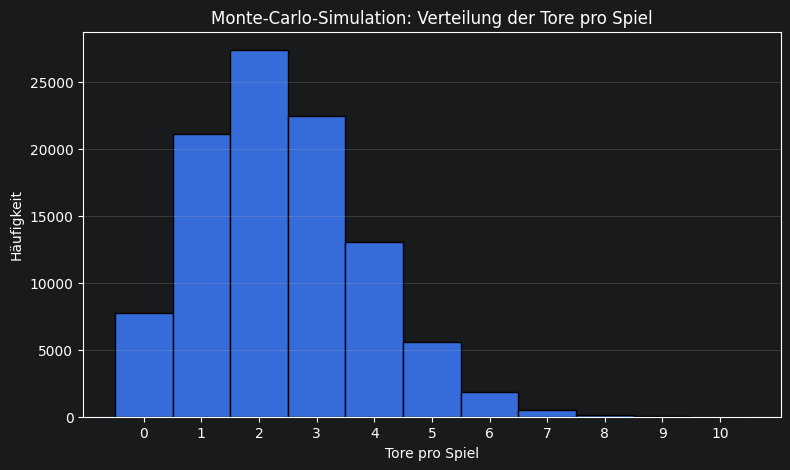

In [4]:
plt.figure(figsize=(9, 5))

bins = np.arange(tore_pro_spiel.min(), tore_pro_spiel.max() + 2) - 0.5
plt.hist(tore_pro_spiel, bins=bins, edgecolor="black")

plt.title("Monte-Carlo-Simulation: Verteilung der Tore pro Spiel")
plt.xlabel("Tore pro Spiel")
plt.ylabel("Häufigkeit")
plt.xticks(range(tore_pro_spiel.min(), tore_pro_spiel.max() + 1))
plt.grid(axis="y", alpha=0.3)

plt.show()


## Kurzes Fazit

Mit der Monte-Carlo-Simulation wurde geschätzt, wie wahrscheinlich es ist, dass eine Fußballmannschaft bei 20 Torschüssen und einer Trefferwahrscheinlichkeit von 12 % mindestens 3 Tore erzielt.

Die Simulation zeigt:

- Die erwartete Toranzahl liegt bei ungefähr **2,4 Toren pro Spiel**.
- Die Toranzahl schwankt typischerweise um etwa **1,45 Tore**.
- Die Wahrscheinlichkeit für mindestens 3 Tore liegt bei ungefähr **43 % bis 44 %**.

Damit eignet sich die Monte-Carlo-Simulation gut, um zufallsabhängige Alltagssituationen wie ein Fußballspiel realistisch zu untersuchen.
